## Automobiles EDA

Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import seaborn as sns

from datetime import datetime
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
%matplotlib inline

In [2]:
# Load the automobiles dataset
automobiles_df = pd.read_csv('automobile.txt')

### Data Cleansing
#### Clean the data

Identify columns that are redundant or unnecessary. It is always easier to make your decisions based on data which is relevant and concise. Remove the following columns `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [3]:
# Checking the size of the dataframe
automobiles_df.shape

(205, 26)

In [4]:
# showing the first 5 rows of the data
automobiles_df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [5]:
# checking the amount of the missing data per column
missing_values_count = automobiles_df.isnull().sum()

# Look at the number of missing values in the first ten columns
missing_values_count[0:26]

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

In [6]:
# Replacing all the question marks in all the columns
automobiles_df.replace('?', np.nan, inplace=True)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [7]:
# checking the amount of the missing data per column
missing_values_count = automobiles_df.isnull().sum()

# Look at the number of missing values in the first ten columns
missing_values_count[0:26]

symboling             0
normalized-losses    41
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 4
dtype: int64

#### Remove any duplicate rows

In [8]:
# Removing 'normalised losses' and 'symboling' rows
automobiles_df.drop(['symboling','normalized-losses'],inplace=True, axis=1)

In [9]:
automobiles_df.shape

(205, 24)

#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [10]:
# Removing rows with NaN
automobiles_df.dropna(inplace=True)

Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [11]:
# Checking the datatypes for all the columns
automobiles_df.dtypes

make                     str
fuel-type                str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                     str
stroke                   str
compression-ratio    float64
horsepower               str
peak-rpm                 str
city-mpg               int64
highway-mpg            int64
price                    str
dtype: object

In [12]:
# Checking the data on row 12 onwards
automobiles_df.iloc[:,12:]

,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...
200,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,ohc,four,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,ohc,six,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [13]:
# Changing rows, bore to float, stroke to float, horsepower to integer, peak rpm to integer and price to integer
automobiles_df = automobiles_df.astype({'bore':'float64', 'stroke':'float64', 'horsepower':'int64', 'peak-rpm':'int64', 'price':'int64'})

In [14]:
# Checking the datatypes for all the columns
automobiles_df.dtypes

make                     str
fuel-type                str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio    float64
horsepower             int64
peak-rpm               int64
city-mpg               int64
highway-mpg            int64
price                  int64
dtype: object

### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

In [15]:
# Create a dataframe with all the cars in the "hatchback" category
hatchback_cars = automobiles_df[automobiles_df["body-style"] == "hatchback"]

In [16]:
hatchback_cars.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
18,chevrolet,gas,std,two,hatchback,fwd,front,88.4,141.1,60.3,...,61,2bbl,2.91,3.03,9.50,48,5100,47,53,5151
19,chevrolet,gas,std,two,hatchback,fwd,front,94.5,155.9,63.6,...,90,2bbl,3.03,3.11,9.60,70,5400,38,43,6295
21,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.41,68,5500,37,41,5572
22,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.40,68,5500,31,38,6377


In [17]:
hatchback_cars.shape

(63, 24)

### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

In [18]:
# Top 5most expensive cars
top5_expensive = automobiles_df.nlargest(5, 'price')[['make', 'body-style', 'engine-size', 'horsepower', 'city-mpg', 'highway-mpg', 'price']]
top5_expensive

,make,body-style,engine-size,horsepower,city-mpg,highway-mpg,price
74,mercedes-benz,hardtop,304,184,14,16,45400
16,bmw,sedan,209,182,16,22,41315
73,mercedes-benz,sedan,308,184,14,16,40960
128,porsche,convertible,194,207,17,25,37028
17,bmw,sedan,209,182,15,20,36880


In [19]:
# Top 5 cheapest cars
top5_cheapest = automobiles_df.nsmallest(5, 'price')[['make', 'body-style', 'engine-size', 'horsepower', 'city-mpg', 'highway-mpg', 'price']]
top5_cheapest

,make,body-style,engine-size,horsepower,city-mpg,highway-mpg,price
138,subaru,hatchback,97,69,31,36,5118
18,chevrolet,hatchback,61,48,47,53,5151
50,mazda,hatchback,91,68,30,31,5195
150,toyota,hatchback,92,62,35,39,5348
76,mitsubishi,hatchback,92,68,37,41,5389


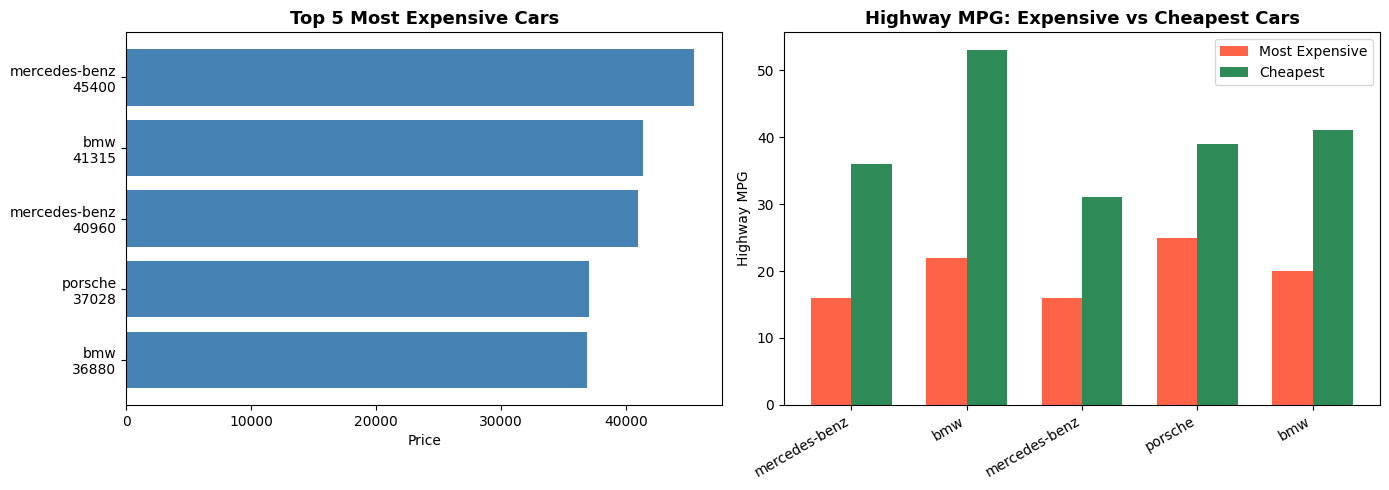

In [29]:
# Visual comparison: most expensive vs cheapest cars
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price bars
top5_expensive_plot = automobiles_df.nlargest(5, 'price')[['make', 'price']].copy()
top5_expensive_plot['label'] = top5_expensive_plot['make'] + '\n' + top5_expensive_plot['price'].astype(str)
axes[0].barh(top5_expensive_plot['label'], top5_expensive_plot['price'], color='steelblue')
axes[0].set_title('Top 5 Most Expensive Cars', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price')
axes[0].invert_yaxis()

# MPG comparison between top expensive and top cheap
top5_cheap_mpg = automobiles_df.nsmallest(5, 'price')[['make', 'city-mpg', 'highway-mpg']]
top5_exp_mpg   = automobiles_df.nlargest(5, 'price')[['make', 'city-mpg', 'highway-mpg']]

x = np.arange(5)
width = 0.35
axes[1].bar(x - width/2, top5_exp_mpg['highway-mpg'].values,  width, label='Most Expensive', color='tomato')
axes[1].bar(x + width/2, top5_cheap_mpg['highway-mpg'].values, width, label='Cheapest',       color='seagreen')
axes[1].set_xticks(x)
axes[1].set_xticklabels(top5_exp_mpg['make'].values, rotation=30, ha='right')
axes[1].set_title('Highway MPG: Expensive vs Cheapest Cars', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Highway MPG')
axes[1].legend()

plt.tight_layout()
plt.show()

#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

In [21]:
# Calculating the average combined MPG per manifacturer
automobiles_df['avg-mpg'] = (automobiles_df['city-mpg'] + automobiles_df['highway-mpg']) / 2

avg_mpg_by_make = automobiles_df.groupby('make')['avg-mpg'].mean().sort_values(ascending=False).reset_index()
avg_mpg_by_make.columns = ['Manufacturer', 'Avg MPG']
avg_mpg_by_make['Avg MPG'] = avg_mpg_by_make['Avg MPG'].round(1)

avg_mpg_by_make

,Manufacturer,Avg MPG
0,chevrolet,43.7
1,honda,32.9
2,volkswagen,31.8
3,dodge,31.6
4,plymouth,31.1
5,mazda,31.0
6,toyota,30.2
7,nissan,30.0
8,subaru,28.5
9,mitsubishi,28.0


C:\Users\Administrator\AppData\Local\Temp\ipykernel_10040\2658425223.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(avg_mpg_by_make['Manufacturer'], rotation=45, ha='right')


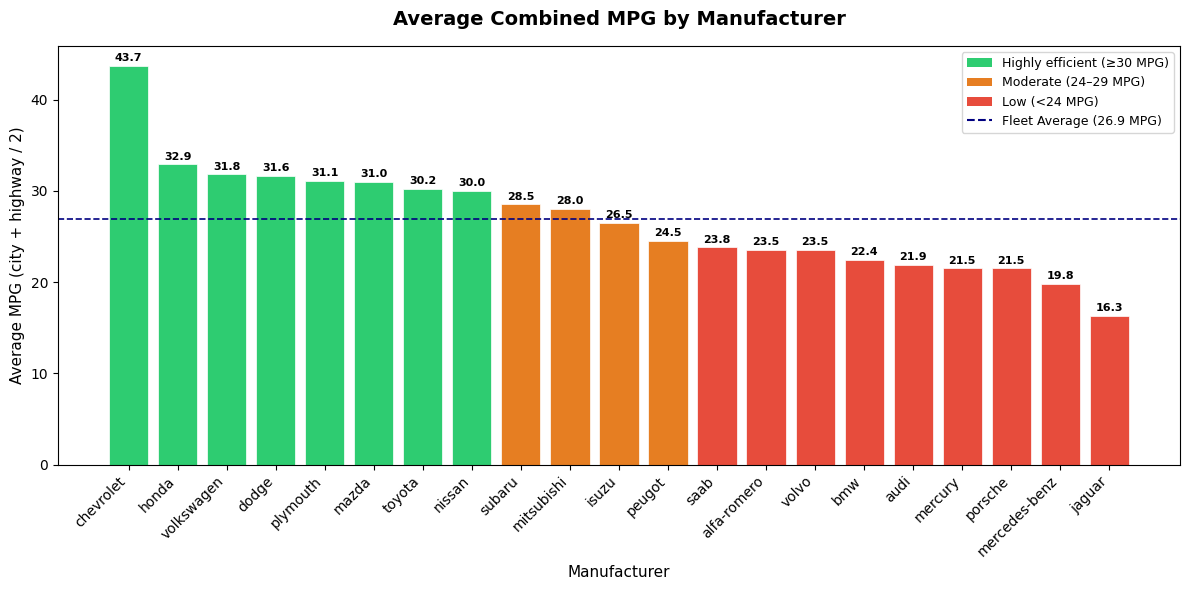

In [22]:
# Bar plot: average MPG by manufacturer
fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#2ecc71' if mpg >= 30 else '#e67e22' if mpg >= 24 else '#e74c3c'
          for mpg in avg_mpg_by_make['Avg MPG']]

bars = ax.bar(avg_mpg_by_make['Manufacturer'], avg_mpg_by_make['Avg MPG'], color=colors, edgecolor='white', linewidth=0.5)

# Annotate bars
for bar, val in zip(bars, avg_mpg_by_make['Avg MPG']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_title('Average Combined MPG by Manufacturer', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Manufacturer', fontsize=11)
ax.set_ylabel('Average MPG (city + highway / 2)', fontsize=11)
ax.set_xticklabels(avg_mpg_by_make['Manufacturer'], rotation=45, ha='right')
ax.axhline(y=avg_mpg_by_make['Avg MPG'].mean(), color='navy', linestyle='--', linewidth=1.2, label=f'Fleet Average ({avg_mpg_by_make["Avg MPG"].mean():.1f} MPG)')
ax.legend()

legend_elements = [Patch(facecolor='#2ecc71', label='Highly efficient (≥30 MPG)'),
                   Patch(facecolor='#e67e22', label='Moderate (24–29 MPG)'),
                   Patch(facecolor='#e74c3c', label='Low (<24 MPG)')]
ax.legend(handles=legend_elements + [plt.Line2D([0], [0], color='navy', linestyle='--', label=f'Fleet Average ({avg_mpg_by_make["Avg MPG"].mean():.1f} MPG)')],
          loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

In [23]:
# Sorting the engine sizes in descending order and displaying the top 10
largest_engines = automobiles_df.sort_values('engine-size', ascending=False)

top10_engines = largest_engines[['make', 'body-style', 'engine-size', 'num-of-cylinders',
                                   'horsepower', 'price', 'city-mpg', 'highway-mpg']].head(10).reset_index(drop=True)
top10_engines.index += 1
top10_engines

,make,body-style,engine-size,num-of-cylinders,horsepower,price,city-mpg,highway-mpg
1,jaguar,sedan,326,twelve,262,36000,13,17
2,mercedes-benz,sedan,308,eight,184,40960,14,16
3,mercedes-benz,hardtop,304,eight,184,45400,14,16
4,jaguar,sedan,258,six,176,32250,15,19
5,jaguar,sedan,258,six,176,35550,15,19
6,mercedes-benz,sedan,234,eight,155,34184,16,18
7,mercedes-benz,convertible,234,eight,155,35056,16,18
8,bmw,sedan,209,six,182,36880,15,20
9,bmw,sedan,209,six,182,41315,16,22
10,bmw,sedan,209,six,182,30760,16,22


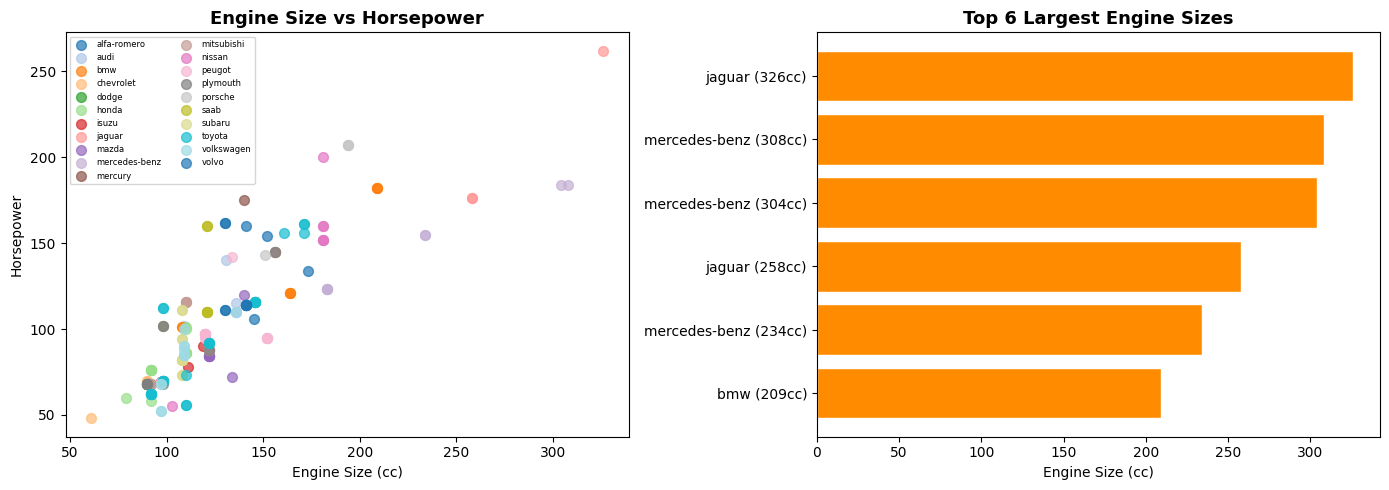

In [30]:
# Visualising the engine size and horsepower with coloured by make
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: engine size vs horsepower
makes = automobiles_df['make'].unique()
palette = sns.color_palette('tab20', len(makes))
make_color = dict(zip(makes, palette))

for make, group in automobiles_df.groupby('make'):
    axes[0].scatter(group['engine-size'], group['horsepower'],
                    label=make, color=make_color[make], alpha=0.7, s=50)

axes[0].set_title('Engine Size vs Horsepower', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Engine Size (cc)')
axes[0].set_ylabel('Horsepower')
axes[0].legend(fontsize=6, ncol=2, loc='upper left')

# Top 10 largest engines bar chart
top10_label = top10_engines['make'] + ' (' + top10_engines['engine-size'].astype(str) + 'cc)'
axes[1].barh(top10_label, top10_engines['engine-size'], color='darkorange', edgecolor='white')
axes[1].set_title('Top 6 Largest Engine Sizes', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Engine Size (cc)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

#### Which vehicle manufacturer has the most car models in the dataset

In [25]:
# Counting models per manufacturer
model_counts = automobiles_df['make'].value_counts().reset_index()
model_counts.columns = ['Manufacturer', 'Number of Models']
model_counts

,Manufacturer,Number of Models
0,toyota,32
1,nissan,18
2,honda,13
3,mitsubishi,13
4,mazda,12
5,subaru,12
6,volkswagen,12
7,peugot,11
8,volvo,11
9,bmw,8


C:\Users\Administrator\AppData\Local\Temp\ipykernel_10040\4053565473.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_counts['Manufacturer'], rotation=45, ha='right')


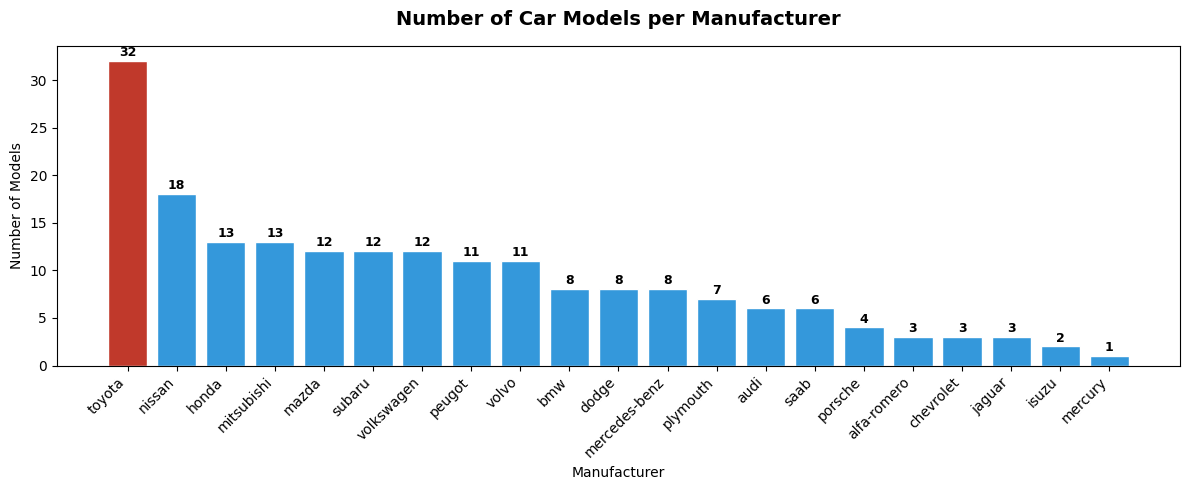

In [26]:
# Bar plot for models per manufacturer
fig, ax = plt.subplots(figsize=(12, 5))

colors = ['#c0392b' if c == model_counts['Number of Models'].max() else '#3498db'
          for c in model_counts['Number of Models']]

bars = ax.bar(model_counts['Manufacturer'], model_counts['Number of Models'], color=colors, edgecolor='white')

for bar, val in zip(bars, model_counts['Number of Models']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            str(val), ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('Number of Car Models per Manufacturer', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Manufacturer')
ax.set_ylabel('Number of Models')
ax.set_xticklabels(model_counts['Manufacturer'], rotation=45, ha='right')

plt.tight_layout()
plt.show()